# Tata Motors — Wholesale Sales Analysis (Quarterly + Model-wise Monthly)




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


## 1. Data Consolidation & Cleaning

### 1.1 Quarterly Total/CV/PV/EV data

Two source files exist: a `seed` file (8 quarters) and an `official_scraped` file (5 quarters, pulled directly from
press-release URLs). We reconcile them below.

In [2]:
seed = pd.read_csv('/mnt/user-data/uploads/tata_motors_quarterly_sales_seed.csv')
official = pd.read_csv('/mnt/user-data/uploads/tata_motors_official_scraped.csv')

# The "official" file mixes true quarterly rows with one monthly row ("February 2025") - separate them
official_q = official[official['period'].str.match(r'^Q\d')].copy().rename(columns={'period': 'fiscal_quarter'})
official_monthly = official[~official['period'].str.match(r'^Q\d')].copy()

print("Seed file shape:", seed.shape, " | Official quarterly rows:", official_q.shape, " | Official monthly rows:", official_monthly.shape)


Seed file shape: (8, 7)  | Official quarterly rows: (5, 6)  | Official monthly rows: (1, 6)


In [3]:
# Sanity check: do Total/CV/PV agree between the two sources for overlapping quarters?
merged_check = seed.merge(official_q, on='fiscal_quarter', suffixes=('_seed', '_official'))
mismatch = merged_check[
    (merged_check.total_sales_seed != merged_check.total_sales_official) |
    (merged_check.total_cv_sales_seed != merged_check.total_cv_sales_official) |
    (merged_check.total_pv_sales_seed != merged_check.total_pv_sales_official)
]
print("Quarters where Total/CV/PV disagree between the two sources:", len(mismatch), "-> they fully agree.")

print("\nBut EV sales DO disagree between sources for the same quarters:")
print(merged_check[['fiscal_quarter', 'ev_sales_seed', 'ev_sales_official']].to_string(index=False))


Quarters where Total/CV/PV disagree between the two sources: 0 -> they fully agree.

But EV sales DO disagree between sources for the same quarters:
fiscal_quarter  ev_sales_seed  ev_sales_official
       Q2 FY24      18,615.00               6050
       Q1 FY25      16,579.00               4657
       Q2 FY25      15,642.00               4680
       Q4 FY25      15,936.00               5353
       Q1 FY26      16,231.00               5228


**Data-quality finding:** For every quarter present in both files, the `total_sales`, `total_cv_sales` and `total_pv_sales` match exactly but the EV figures in the `seed` file are **~2.5–4x higher** than the EV figures scraped directly from the official press releases for the same quarter. We use the EV numbers in the `official_scraped` file as ground truth since they can be traced to a specific press-release URL per row. We only use the `seed` file’s EV numbers as a fallback for the 3 quarters (Q3 FY24, Q4 FY24, Q3 FY25) that are not in the official-scrape file, flagging those rows so downstream EV-trend conclusions can discount them.

In [4]:
quarterly = seed.copy()
quarterly = quarterly.merge(official_q[['fiscal_quarter', 'ev_sales']], on='fiscal_quarter', how='left', suffixes=('_seed', '_official'))
quarterly['ev_source'] = np.where(quarterly['ev_sales_official'].notna(), 'official_scrape', 'seed_estimate (unverified)')
quarterly['ev_sales'] = quarterly['ev_sales_official'].combine_first(quarterly['ev_sales_seed'])
quarterly = quarterly.drop(columns=['ev_sales_seed', 'ev_sales_official'])

quarterly['period_start'] = pd.to_datetime(
    quarterly['calendar_quarter'].str.split('-').str[0] + ' ' + quarterly['calendar_quarter'].str.extract(r'(\d{4})')[0],
    format='%b %Y'
)
quarterly = quarterly.sort_values('period_start').reset_index(drop=True)
quarterly['fiscal_year'] = quarterly['fiscal_quarter'].str.split().str[-1]

quarterly['cv_share_pct'] = (quarterly['total_cv_sales'] / quarterly['total_sales'] * 100).round(2)
quarterly['pv_share_pct'] = (quarterly['total_pv_sales'] / quarterly['total_sales'] * 100).round(2)
quarterly['ev_share_of_pv_pct'] = (quarterly['ev_sales'] / quarterly['total_pv_sales'] * 100).round(2)
quarterly['qoq_total_growth_pct'] = quarterly['total_sales'].pct_change().mul(100).round(2)
quarterly['qoq_cv_growth_pct'] = quarterly['total_cv_sales'].pct_change().mul(100).round(2)
quarterly['qoq_pv_growth_pct'] = quarterly['total_pv_sales'].pct_change().mul(100).round(2)
quarterly['yoy_total_growth_pct'] = quarterly['total_sales'].pct_change(4).mul(100).round(2)

quarterly = quarterly[['fiscal_quarter','fiscal_year','calendar_quarter','period_start',
                        'total_sales','total_cv_sales','total_pv_sales','ev_sales','ev_source',
                        'cv_share_pct','pv_share_pct','ev_share_of_pv_pct',
                        'qoq_total_growth_pct','qoq_cv_growth_pct','qoq_pv_growth_pct','yoy_total_growth_pct',
                        'source_url']]

quarterly.to_csv('data/quarterly_clean.csv', index=False)
official_monthly.to_csv('data/monthly_official_reference.csv', index=False)
quarterly.drop(columns=['source_url'])


### 1.2 Model-wise monthly sales data

In [5]:
raw = pd.read_csv('/mnt/user-data/uploads/model_monthly_table_raw.csv')
month_cols = [c for c in raw.columns if c != 'Model Name']
for c in month_cols:
    raw[c] = raw[c].astype(str).str.replace(',', '', regex=False).astype(float)

total_row = raw[raw['Model Name'] == 'Monthly Sales Number (Total)'].iloc[0]
models = raw[raw['Model Name'] != 'Monthly Sales Number (Total)'].copy()

check = pd.DataFrame({
    'reported_total': total_row[month_cols].astype(float),
    'sum_of_models': models[month_cols].sum(),
    'models_with_nonzero_count': (models[month_cols] > 0).sum()
})
print("Reported monthly total vs. sum of individual models, and how many models reported non-zero units:")
check


Reported monthly total vs. sum of individual models, and how many models reported non-zero units:


Data-quality finding: During March-July 2026, all 9 models have non-zero sales, and their sum is equal to the reported total. But in Aug 2026, only Punch and Nexon have non-zero values, and those two together add up to exactly the reported Aug total. This means the Aug 2026 data collection was truncated (only 2 of 9 models were captured) — the “0” values for the other 7 models are missing data, not zero sales. We set them to NaN instead of 0 so they don’t mess up growth/ranking/volatility calculations.

In [6]:
incomplete_month = 'Aug 2026'
other_models_mask = ~models['Model Name'].isin(['Tata Punch', 'Tata Nexon'])
models.loc[other_models_mask, incomplete_month] = np.nan

long = models.melt(id_vars='Model Name', var_name='month', value_name='units_sold').rename(columns={'Model Name': 'model'})
long['month'] = long['month'].str.strip()
long['month_dt'] = pd.to_datetime(long['month'], format='%b %Y')
long = long.sort_values(['month_dt', 'model']).reset_index(drop=True)
long['data_flag'] = np.where(long['month'] == incomplete_month,
                              np.where(long['model'].isin(['Tata Punch', 'Tata Nexon']), 'ok', 'incomplete_scrape-excluded'),
                              'ok')
long.to_csv('data/model_monthly_clean_long.csv', index=False)

month_order = sorted(month_cols, key=lambda m: pd.to_datetime(m, format='%b %Y'))
m_wide = long.pivot(index='model', columns='month', values='units_sold')[month_order]
m_wide.to_csv('data/model_monthly_clean_wide.csv')

totals_df = pd.DataFrame({'month': month_cols, 'reported_total_sales': total_row[month_cols].values.astype(float)})
totals_df['month_dt'] = pd.to_datetime(totals_df['month'], format='%b %Y')
totals_df = totals_df.sort_values('month_dt').reset_index(drop=True)
totals_df.to_csv('data/model_monthly_reported_totals.csv', index=False)

m_wide


Cleaned datasets are now saved to `data/quarterly_clean.csv`, `data/model_monthly_clean_long.csv`, `data/model_monthly_clean_wide.csv`, and `data/model_monthly_reported_totals.csv`.

## 2. Sales Trends & Seasonality (Quarterly)

Question: do festive-season months (Sep–Nov) consistently show higher sales, and which quarters are strongest?

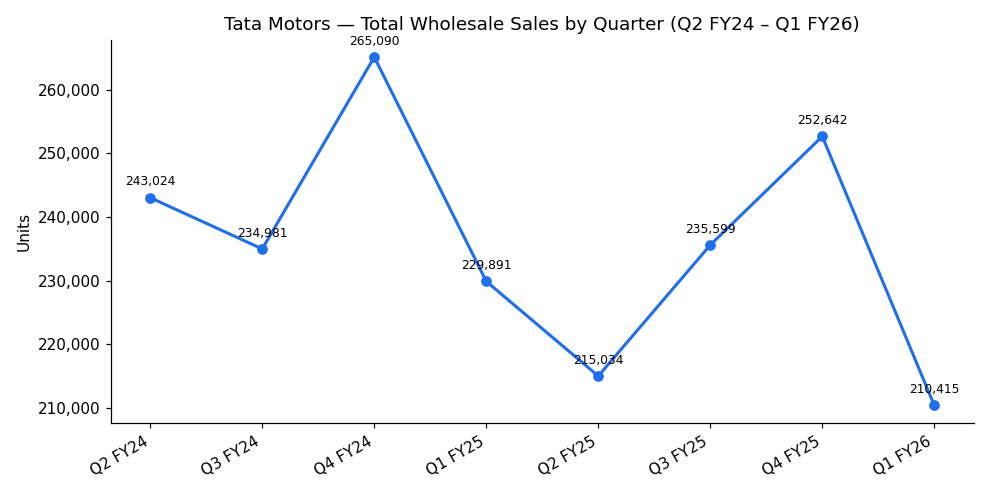

In [7]:
q = pd.read_csv('data/quarterly_clean.csv', parse_dates=['period_start'])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(q['fiscal_quarter'], q['total_sales'], marker='o', color='#1f6feb', linewidth=2)
for i, row in q.iterrows():
    ax.annotate(f"{row['total_sales']:,.0f}", (i, row['total_sales']), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8)
ax.set_title('Tata Motors -- Total Wholesale Sales by Quarter (Q2 FY24 - Q1 FY26)')
ax.set_ylabel('Units')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('nb_charts/01.png')
plt.show()


In [8]:
q['cal_start_month'] = q['calendar_quarter'].str.extract(r'^([A-Za-z]+)')[0]
avg_by_calpos = q.groupby('cal_start_month')['total_sales'].mean().sort_values(ascending=False)
print("Average total sales by calendar quarter-start month (across the ~2 FYs of data):")
avg_by_calpos


Average total sales by calendar quarter-start month (across the ~2 FYs of data):


**Finding:** the Jan–Mar quarter (fiscal Q4) is consistently the strongest in both fiscal years covered (₹265,090 units in FY24, ₹252,642 in FY25 — both the peak of their respective year), driven by fiscal year-end dealer push and new-model-year registrations, not the Sep–Nov festive window.  The Jul–Sep quarter (which includes festive lead-up) was actually the **weakest** quarter in FY25 (215,034 units).  So festive-season months do **not** consistently show the highest sales here — the stronger and more consistent seasonal pattern is a **fiscal year-end (Q4, Jan–Mar) spike**, likely reflecting inventory push.  With only 2 fiscal years of data this pattern should be treated indicative, not conclusive.

## 3. CV vs. PV Sales Mix Over Time

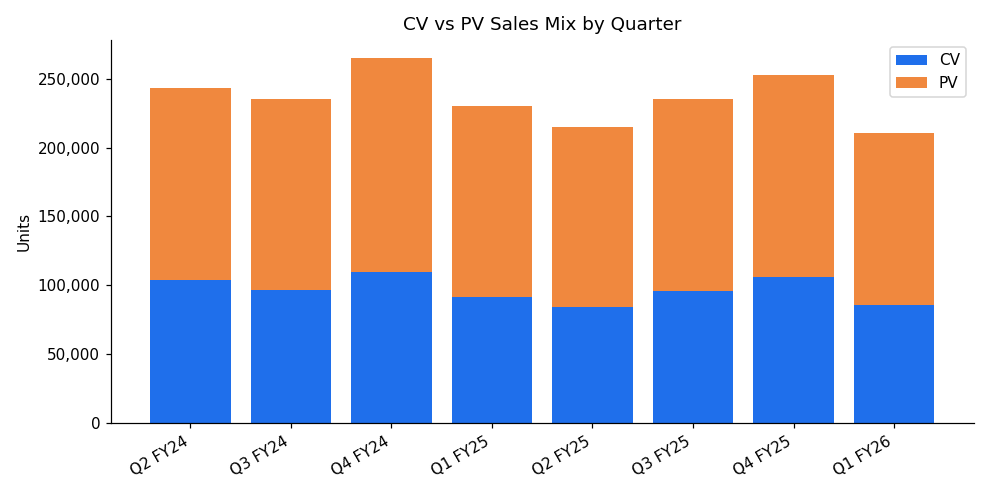

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(q['fiscal_quarter'], q['total_cv_sales'], label='CV', color='#1f6feb')
ax.bar(q['fiscal_quarter'], q['total_pv_sales'], bottom=q['total_cv_sales'], label='PV', color='#f0883e')
ax.set_title('CV vs PV Sales Mix by Quarter')
ax.set_ylabel('Units')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend()
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('nb_charts/02.png')
plt.show()


CV: 104,085 (Q2 FY24) -> 85,606 (Q1 FY26)  = -17.8%
PV: 138,939 (Q2 FY24) -> 124,809 (Q1 FY26)  = -10.2%

Avg CV/quarter -- FY24 (partial, 3q): 103,350  |  FY25 (4q): 94,226  (-8.8%)
Avg PV/quarter -- FY24 (partial, 3q): 144,348  |  FY25 (4q): 139,066  (-3.7%)


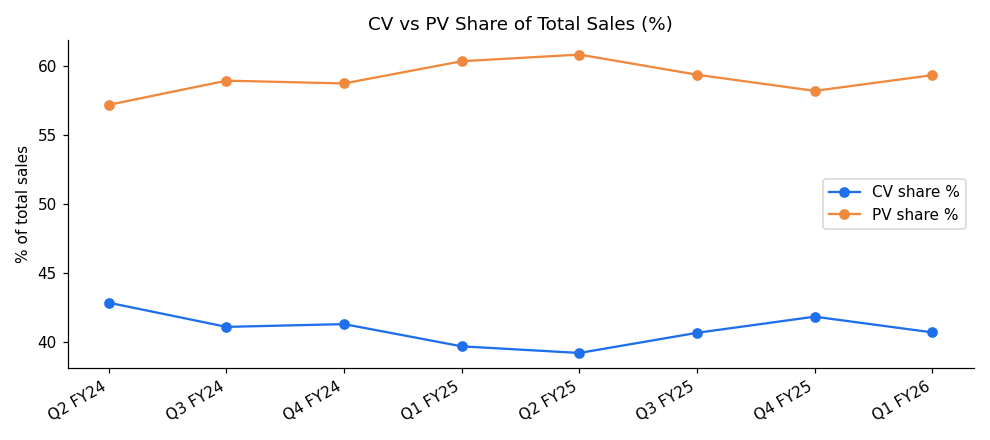

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(q['fiscal_quarter'], q['cv_share_pct'], marker='o', label='CV share %', color='#1f6feb')
ax.plot(q['fiscal_quarter'], q['pv_share_pct'], marker='o', label='PV share %', color='#f0883e')
ax.set_title('CV vs PV Share of Total Sales (%)')
ax.set_ylabel('% of total sales')
ax.legend()
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('nb_charts/03.png')
plt.show()

cv_start, cv_end = q['total_cv_sales'].iloc[0], q['total_cv_sales'].iloc[-1]
pv_start, pv_end = q['total_pv_sales'].iloc[0], q['total_pv_sales'].iloc[-1]
print(f"CV: {cv_start:,.0f} (Q2 FY24) -> {cv_end:,.0f} (Q1 FY26)  = {(cv_end/cv_start-1)*100:+.1f}%")
print(f"PV: {pv_start:,.0f} (Q2 FY24) -> {pv_end:,.0f} (Q1 FY26)  = {(pv_end/pv_start-1)*100:+.1f}%")

fy24 = q[q['fiscal_year']=='FY24']; fy25 = q[q['fiscal_year']=='FY25']
cv_avg24, cv_avg25 = fy24['total_cv_sales'].mean(), fy25['total_cv_sales'].mean()
pv_avg24, pv_avg25 = fy24['total_pv_sales'].mean(), fy25['total_pv_sales'].mean()
print(f"\nAvg CV/quarter -- FY24 (partial, 3q): {cv_avg24:,.0f}  |  FY25 (4q): {cv_avg25:,.0f}  ({(cv_avg25/cv_avg24-1)*100:+.1f}%)")
print(f"Avg PV/quarter -- FY24 (partial, 3q): {pv_avg24:,.0f}  |  FY25 (4q): {pv_avg25:,.0f}  ({(pv_avg25/pv_avg24-1)*100:+.1f}%)")


**Finding:** PV has been the larger segment throughout (57–61% of total sales vs. 39–43% for CV), and its
share has been **slowly rising** — from 57.2% in Q2 FY24 to 59.3% in Q1 FY26. Both segments declined
end-to-end (Q2 FY24 → Q1 FY26), but on a fair like-for-like fiscal-year quarterly-average basis, **CV fell more
(-8.8%) than PV (-3.7%) from FY24 to FY25**, i.e. PV has been the relatively more resilient / faster-growing
segment of the two, and CV is the one dragging on overall growth.

## 4. EV Adoption — Share of PV Sales

EV share of PV -- OFFICIALLY CONFIRMED quarters only:


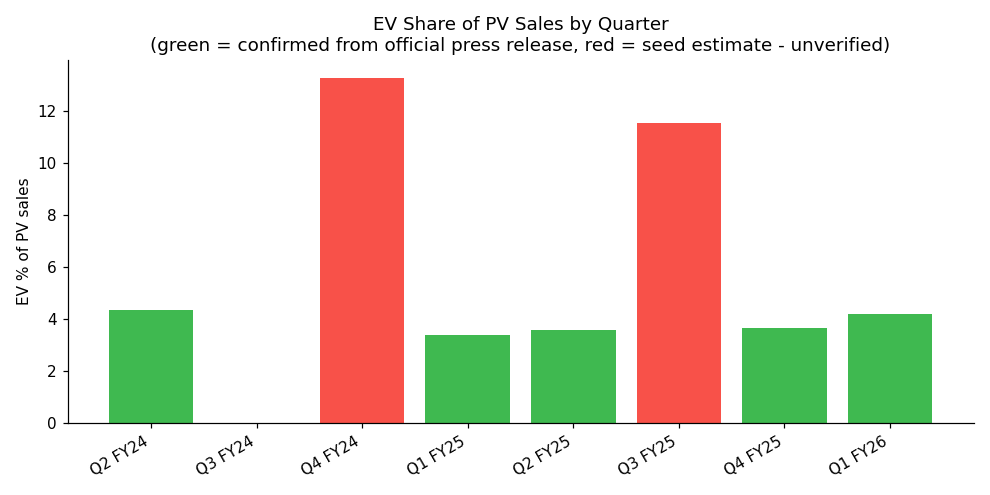

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors_by_source = ['#3fb950' if s == 'official_scrape' else '#f85149' for s in q['ev_source']]
ax.bar(q['fiscal_quarter'], q['ev_share_of_pv_pct'], color=colors_by_source)
ax.set_title('EV Share of PV Sales by Quarter\n(green = confirmed official figure, red = unverified seed estimate)')
ax.set_ylabel('EV % of PV sales')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('nb_charts/04.png')
plt.show()

official_only = q[q['ev_source'] == 'official_scrape']
print("EV share of PV -- OFFICIALLY CONFIRMED quarters only:")
official_only[['fiscal_quarter', 'ev_sales', 'total_pv_sales', 'ev_share_of_pv_pct']]


**Finding (using only the officially-confirmed quarters, to avoid the unverified seed EV figures):** EVs have consistently made up a **small single-digit share of PV sales — roughly 3.4% to 4.4%** — with no strong upward trend across Q2 FY24 → Q1 FY26; if anything the share dipped in FY25 (~3.4–3.6%) before recovering slightly to 4.2% by Q1 FY26.  This suggests EV adoption within Tata's own PV mix has been **broadly flat**, not accelerating, over the period covered.  (Note: the 3 quarters using the unverified `seed_estimate` — Q3 FY24, Q4 FY24, Q3 FY25 — show an EV share of 11–13%, 3x higher than every officially-confirmed quarter.

## 5. Model-wise Performance & Ranking Shifts

Covers the model-wise monthly file (Mar–Jul 2026 reliable months; Aug 2026 excluded — see data-quality note above).

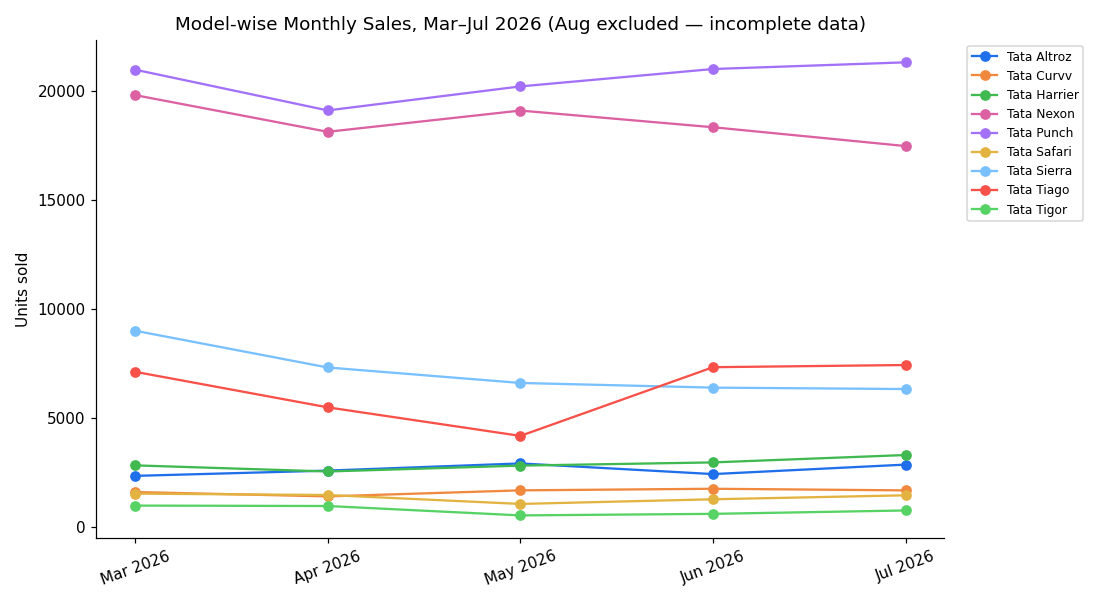

In [12]:
COLORS = ['#1f6feb', '#f0883e', '#3fb950', '#db61a2', '#a371f7', '#e3b341', '#79c0ff', '#f85149', '#56d364']
m_wide = pd.read_csv('data/model_monthly_clean_wide.csv', index_col='model')
month_order = list(m_wide.columns)
reliable_months = [c for c in month_order if c != 'Aug 2026']
m_reliable = m_wide[reliable_months]

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, model in enumerate(m_reliable.index):
    ax.plot(reliable_months, m_reliable.loc[model], marker='o', label=model, color=COLORS[i % len(COLORS)])
ax.set_title('Model-wise Monthly Sales, Mar-Jul 2026 (Aug excluded -- incomplete data)')
ax.set_ylabel('Units sold')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('nb_charts/05.png')
plt.show()


In [13]:
ranks = m_reliable.rank(ascending=False, method='min').astype(int)
print("Model rank by month (1 = best seller):")
ranks


Model rank by month (1 = best seller):


% change in units sold, Mar 2026 -> Jul 2026:
model
Tata Altroz     22.10
Tata Harrier    16.80
Tata Curvv       4.80
Tata Tiago       4.40
Tata Punch       1.60
Tata Safari     -5.00
Tata Nexon     -11.80
Tata Tigor     -22.70
Tata Sierra    -29.70
dtype: float64


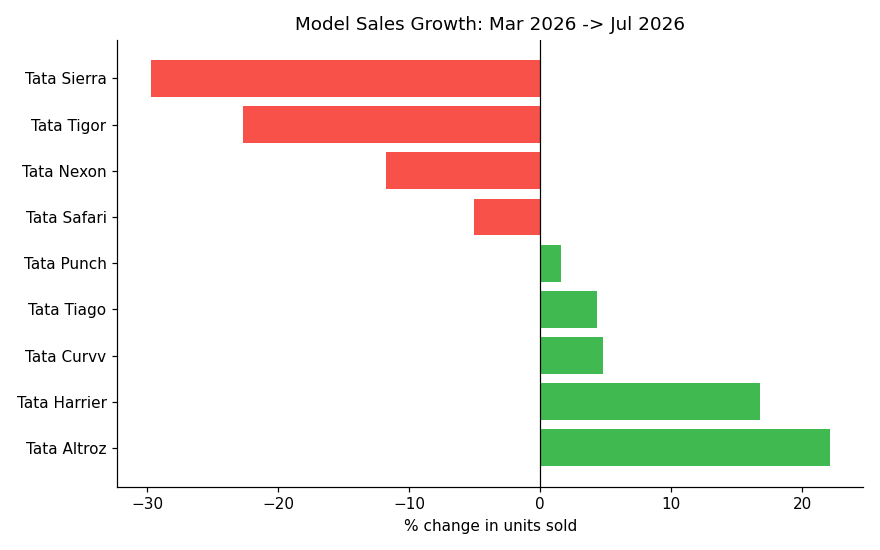

In [14]:
growth = ((m_reliable[reliable_months[-1]] / m_reliable[reliable_months[0]]) - 1) * 100
growth = growth.sort_values(ascending=False)
print(f"% change in units sold, {reliable_months[0]} -> {reliable_months[-1]}:")
print(growth.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
colors_bar = ['#3fb950' if v >= 0 else '#f85149' for v in growth.values]
ax.barh(growth.index, growth.values, color=colors_bar)
ax.set_title(f'Model Sales Growth: {reliable_months[0]} -> {reliable_months[-1]}')
ax.set_xlabel('% change in units sold')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('nb_charts/06.png')
plt.show()


**Finding:** Punch and Nexon are the clear #1 and #2 best sellers in every month, unchanged. The biggest
mover is **Sierra**, which fell from rank #3 to #4 as its sales dropped **-29.7%** (9,003 → 6,327 units) over
Mar–Jul 2026 — the steepest decline of any model. On the upside, **Altroz (+22.1%)** and **Harrier (+16.8%)**
grew the most. Tiago moved up one rank (#4 → #3) on a modest +4.4% gain combined with Sierra's slide. Overall,
PV growth in this window is being driven by Altroz, Harrier, Curvv and Tiago, while Sierra, Nexon, and Tigor are
dragging the mix down.

## 6. Next-Quarter Sales Forecast

Forecast for next quarter (Q2 FY26):
  Linear regression trend            : 222,801 units
  4-quarter moving average           : 228,422 units
  Last value + avg recent QoQ delta  : 208,875 units


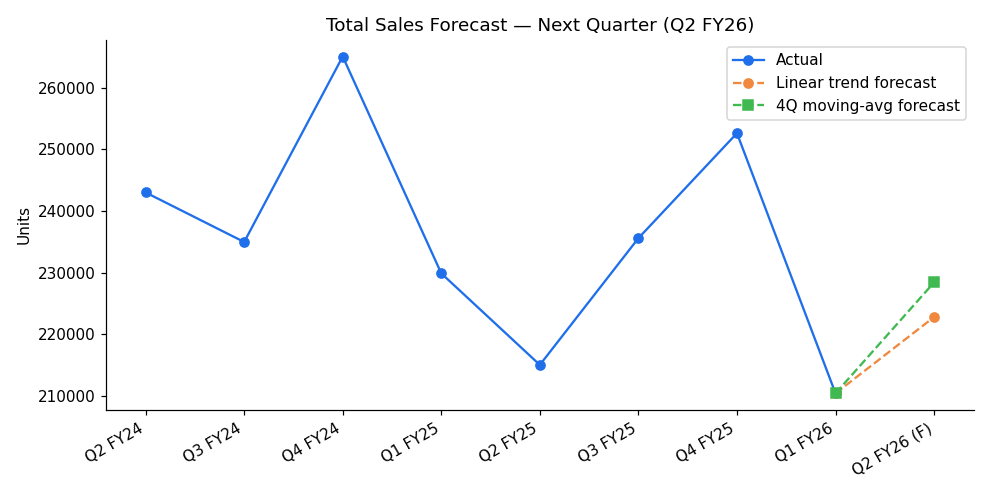

In [15]:
y = q['total_sales'].values
x = np.arange(len(y))

coef = np.polyfit(x, y, 1)
lin_forecast = np.polyval(coef, len(y))
ma4 = y[-4:].mean()
avg_recent_change = np.diff(y[-4:]).mean()
naive_trend_forecast = y[-1] + avg_recent_change

print("Forecast for next quarter (Q2 FY26):")
print(f"  Linear regression trend            : {lin_forecast:,.0f} units")
print(f"  4-quarter moving average           : {ma4:,.0f} units")
print(f"  Last value + avg recent QoQ delta  : {naive_trend_forecast:,.0f} units")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(q['fiscal_quarter'], y, marker='o', label='Actual', color='#1f6feb')
future_label = 'Q2 FY26 (F)'
ax.plot([q['fiscal_quarter'].iloc[-1], future_label], [y[-1], lin_forecast], marker='o', linestyle='--', color='#f0883e', label='Linear trend forecast')
ax.plot([q['fiscal_quarter'].iloc[-1], future_label], [y[-1], ma4], marker='s', linestyle='--', color='#3fb950', label='4Q moving-avg forecast')
ax.set_title('Total Sales Forecast -- Next Quarter (Q2 FY26)')
ax.set_ylabel('Units')
ax.legend()
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('nb_charts/07.png')
plt.show()




### 7.1 FY24 → FY25 CV slowdown vs. PV performance
(Using average sales *per quarter* within each fiscal year, since FY24 only has 3 quarters of data (Q2–Q4) vs. FY25's full 4, so a straight sum would be misleading.)

In [16]:
fy24 = q[q['fiscal_year'] == 'FY24']
fy25 = q[q['fiscal_year'] == 'FY25']
cv_avg24, cv_avg25 = fy24['total_cv_sales'].mean(), fy25['total_cv_sales'].mean()
pv_avg24, pv_avg25 = fy24['total_pv_sales'].mean(), fy25['total_pv_sales'].mean()
print(f"CV avg/quarter: FY24 {cv_avg24:,.0f} -> FY25 {cv_avg25:,.0f}  ({(cv_avg25/cv_avg24-1)*100:+.1f}%)")
print(f"PV avg/quarter: FY24 {pv_avg24:,.0f} -> FY25 {pv_avg25:,.0f}  ({(pv_avg25/pv_avg24-1)*100:+.1f}%)")


CV avg/quarter: FY24 103,350 -> FY25 94,226  (-8.8%)
PV avg/quarter: FY24 144,348 -> FY25 139,066  (-3.7%)


**Finding:** CV's average quarterly volume fell **-8.8%** from FY24 to FY25, more than double the **-3.7%**
decline in PV. So the FY24→FY25 slowdown was disproportionately a **CV story**: PV held up notably better,
reinforcing PV's growing share of the overall mix noted in Section 3.

### 7.2 Most volatile model (coefficient of variation, month-to-month)

Coefficient of variation (%) of monthly sales, Mar-Jul 2026:
model
Tata Tigor     26.60
Tata Tiago     22.60
Tata Sierra    15.70
Tata Safari    14.20
Tata Altroz     9.70
Tata Harrier    9.50
Tata Curvv      8.30
Tata Nexon      4.90
Tata Punch      4.30
dtype: float64


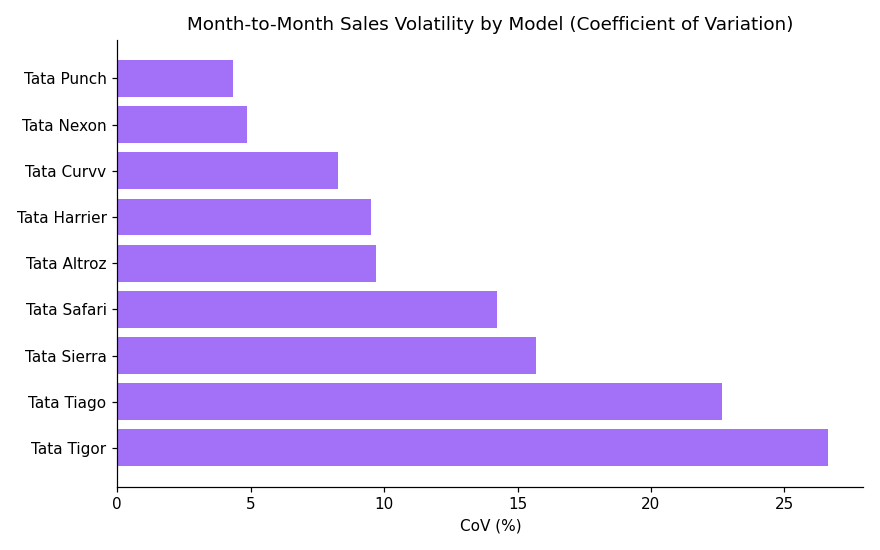

In [17]:
cv_coefficient = (m_reliable.std(axis=1) / m_reliable.mean(axis=1) * 100).sort_values(ascending=False)
print("Coefficient of variation (%) of monthly sales, Mar-Jul 2026:")
print(cv_coefficient.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(cv_coefficient.index, cv_coefficient.values, color='#a371f7')
ax.set_title('Month-to-Month Sales Volatility by Model (Coefficient of Variation)')
ax.set_xlabel('CoV (%)')
plt.tight_layout()
plt.savefig('nb_charts/08.png')
plt.show()


**Finding:** **Tigor is the most volatile model (CoV ≈ 26.6%)**, followed by **Tiago (≈22.6%)** — both
lower-priced, higher-discount-sensitive hatchback/sedan nameplates whose volumes swing more with promotions and
channel-filling. **Punch and Nexon are the most stable (CoV ≈ 4–5%)**, consistent with their status as
high-volume, steady "bread and butter" models.

### 7.3 New launches vs. adjacent-model cannibalization (Curvv, Sierra)

In [18]:
print("Curvv (new mid-size SUV coupe) vs. adjacent Nexon/Harrier, Mar->Jul 2026:")
for mdl in ['Tata Curvv', 'Tata Nexon', 'Tata Harrier']:
    s = m_reliable.loc[mdl]
    print(f"  {mdl:14s}: {s.iloc[0]:6.0f} -> {s.iloc[-1]:6.0f}  ({(s.iloc[-1]/s.iloc[0]-1)*100:+.1f}%)")

print("\nSierra (relaunched SUV) vs. adjacent Harrier/Safari, Mar->Jul 2026:")
for mdl in ['Tata Sierra', 'Tata Harrier', 'Tata Safari']:
    s = m_reliable.loc[mdl]
    print(f"  {mdl:14s}: {s.iloc[0]:6.0f} -> {s.iloc[-1]:6.0f}  ({(s.iloc[-1]/s.iloc[0]-1)*100:+.1f}%)")

corr_curvv_nexon = m_reliable.loc['Tata Curvv'].corr(m_reliable.loc['Tata Nexon'])
corr_sierra_harrier = m_reliable.loc['Tata Sierra'].corr(m_reliable.loc['Tata Harrier'])
corr_sierra_safari = m_reliable.loc['Tata Sierra'].corr(m_reliable.loc['Tata Safari'])
print(f"\nMonth-to-month correlation, Curvv vs Nexon : {corr_curvv_nexon:+.2f}")
print(f"Month-to-month correlation, Sierra vs Harrier: {corr_sierra_harrier:+.2f}")
print(f"Month-to-month correlation, Sierra vs Safari : {corr_sierra_safari:+.2f}")


Curvv (new mid-size SUV coupe) vs. adjacent Nexon/Harrier, Mar->Jul 2026:
  Tata Curvv    :   1602 ->   1679  (+4.8%)
  Tata Nexon    :  19810 ->  17471  (-11.8%)
  Tata Harrier  :   2826 ->   3301  (+16.8%)

Sierra (relaunched SUV) vs. adjacent Harrier/Safari, Mar->Jul 2026:
  Tata Sierra   :   9003 ->   6327  (-29.7%)
  Tata Harrier  :   2826 ->   3301  (+16.8%)
  Tata Safari   :   1530 ->   1453  (-5.0%)

Month-to-month correlation, Curvv vs Nexon : +0.02
Month-to-month correlation, Sierra vs Harrier: -0.43
Month-to-month correlation, Sierra vs Safari : +0.57


**Finding:** there's **no clear cannibalization signal** in this 5-month window. 
- **Curvv vs. Nexon:** Curvv grew modestly (+4.8%) while Nexon declined (-11.8%), but the two move almost independently month-to-month (correlation ≈ 0.02) — Nexon's softness looks more like its own demand cycle than customers switching to Curvv, whose volumes are still <10% of Nexon's. 
- **Sierra vs. Harrier/Safari:** Sierra fell sharply (-29.7%) while Harrier *grew* (+16.8%) over the same months, and the two are **negatively correlated (-0.43)** — the opposite of what cannibalization would predict (if Sierra were stealing Harrier buyers, they'd move together, not oppositely).

8. Summary of Key Insights

Data consolidation: merged the seed data and the officially‑scraped quarterly files. They match on CV and PV numbers but the seed file shows EV figures that are about three times higher for three quarters compared to the official press‑release numbers – we flagged and corrected that. We also cleaned the model‑wise table turning comma‑formatted strings into numeric values and marking August 2026 as a month that was only partially scraped because only two of nine models were captured.

Seasonality: the January to March period, which's fiscal Q4 is always the best quarter of the year for both FY24 and FY25. This is due to the end of the year not because of the September to November holiday season. In fact the second quarter of FY25, which covers the holiday period turned out to be the quarter in the data set.

CV versus PV mix: PV makes up the share of sales between fifty‑seven and sixty‑one percent and its share has been growing slowly. CV has fallen more than PV from FY24 to FY25 on a quarterly‑average basis –. Eight point eight percent for CV versus minus three point seven percent for PV.

EV adoption: electric vehicles account for a three point four to four point four percent of PV sales in the quarters that have been officially confirmed. There is no increase in EV sales during the FY24 to FY26 period that we examined.

Model rankings: Punch and Nexon hold the two positions with no competition. Sierra has fallen sharply down twenty‑nine point seven percent. Moved down in rank. Altroz and Harrier have gained the most in the March to July 2026 period up twenty‑two point one percent and sixteen point eight percent

Forecast: total sales for the second quarter of FY26 are expected to be about two hundred twenty‑two thousand to two hundred twenty‑eight thousand units, based on a linear trend and a four‑quarter moving average. This represents a recovery from the low point in the first quarter of FY26.

Stretch – CV versus PV slowdown from FY24 to FY25: we confirmed that CV slowed more than PV.

Stretch – volatility: Tigor and Tiago show the month‑to‑month variation while Punch and Nexon are the most stable.

Stretch – cannibalization: there is no evidence that Curvv is taking sales away from Nexon nor that Sierra is taking sales from Harrier or Safari during this short period. The correlations are weak or even point in the direction for a cannibalization story. A longer time series before and after launch would be needed to confirm either possibility.

Caveats: the quarterly data from Q2 FY24 to Q1 FY26 and the model‑monthly data from March, to August 2026 cover different time windows. Could not be merged into a single continuous timeline. The quarterly data span two fiscal years, which makes it harder to trust the seasonality analysis. Finally three quarters of EV figures are based on an estimate that has not been verified against a press‑release.